# Toy retrieval

Needs `CUTTINGS_CHECKPOINT` in the environment or in a `.env` at the repo root.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch

from cuttings_model.checkpoint import load_backbone
from cuttings_model.embed import crop_features
from cuttings_model.geometry import CROP_SIZE
from cuttings_model.preprocess import lattice_origins, read_cr2_frame, to_batch
from cuttings_model.settings import Settings, resolve_device

IMAGES = sorted(Path("sample").glob("*.CR2"))

settings = Settings()
device = resolve_device(settings.device)
backbone = load_backbone(settings.checkpoint).to(device)
# off the shelf: hub.build("dinov2_vitb14", pretrained=True)

sum(p.numel() for p in backbone.parameters()), backbone.patch_size

Using cache found in /Users/boyegs/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8
/Users/boyegs/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/Users/boyegs/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/Users/boyegs/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


(86580480, 14)

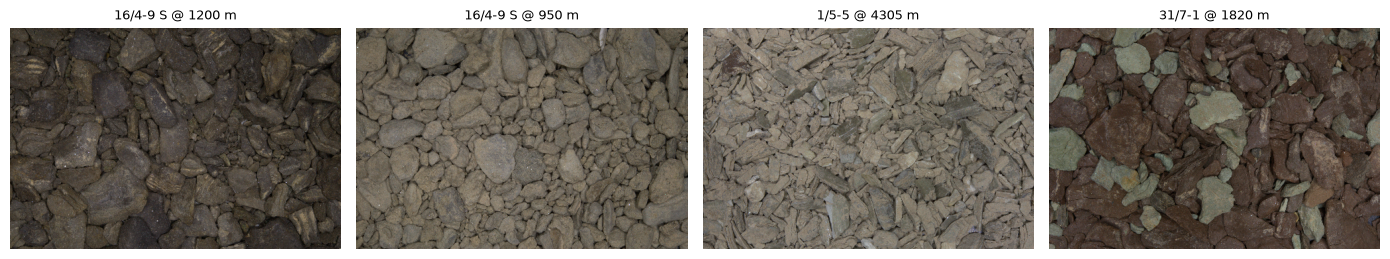

In [2]:
def label(path: Path) -> str:
    well, _, rest = path.name.partition("__")
    centimetres = int(rest.split("_M_")[1].split("_")[0])
    return f"{well.replace('_', '/')} @ {centimetres / 100:.0f} m"


names = [label(path) for path in IMAGES]
frames = [read_cr2_frame(path) for path in IMAGES]

fig, axes = plt.subplots(1, len(frames), figsize=(14, 2.6))
for ax, frame, name in zip(axes, frames, names):
    ax.imshow(frame[::12, ::12])
    ax.set_title(name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [3]:
origins = lattice_origins(frames[0])


def embed_frame(frame):
    batch = to_batch(frame, origins=origins)
    return crop_features(backbone, batch, device=device)


bank = torch.nn.functional.normalize(
    torch.cat([embed_frame(frame) for frame in frames]),
    dim=-1,
)
source = torch.arange(len(frames)).repeat_interleave(len(origins))
print(
    f"{len(frames)} photographs x {len(origins)} crops -> {tuple(bank.shape)}"
)

4 photographs x 442 crops -> (1768, 768)


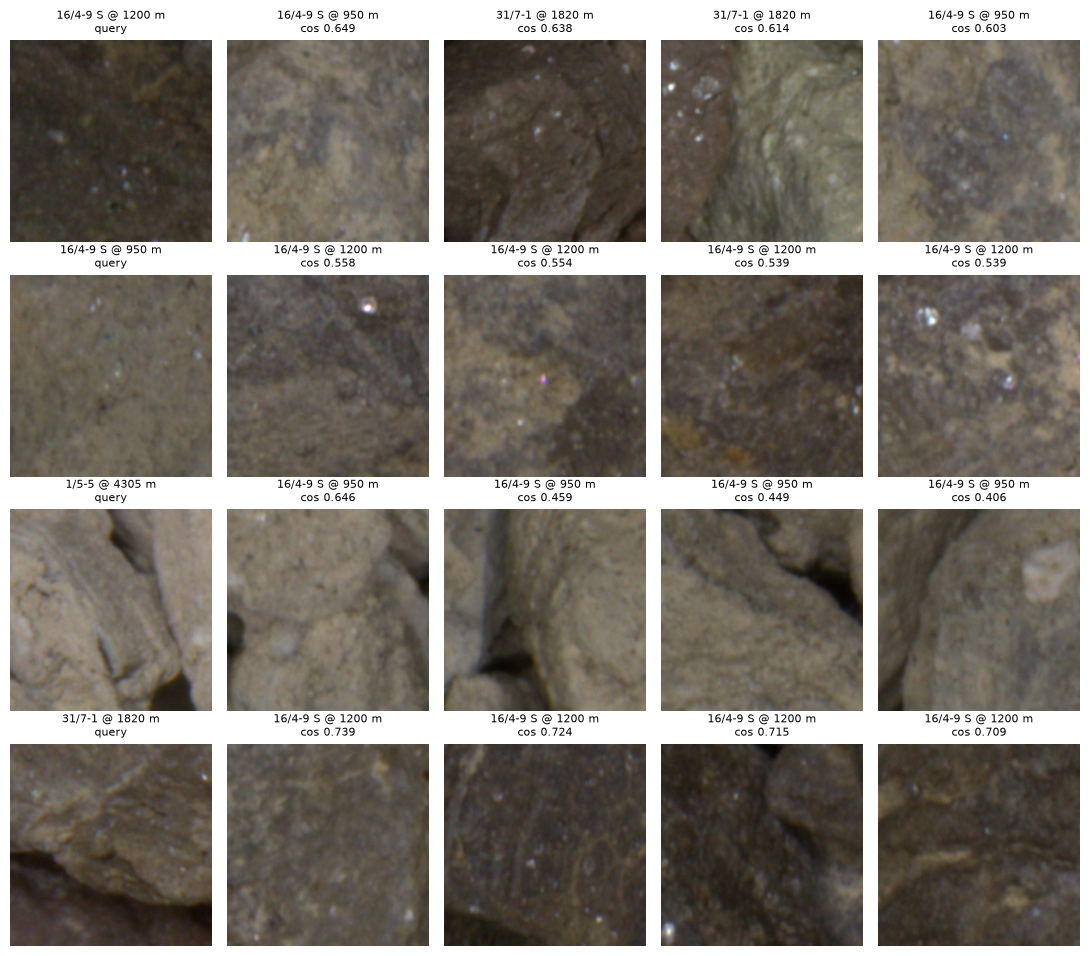

In [4]:
k = 4
similarity = bank @ bank.T


def neighbours(query: int) -> list[tuple[int, str]]:
    elsewhere = torch.where(source == source[query], -1.0, similarity[query])
    return [(query, "query")] + [
        (index, f"cos {similarity[query, index]:.3f}")
        for index in elsewhere.topk(k).indices.tolist()
    ]


def crop_of(index: int):
    top, left = origins[index % len(origins)]
    return frames[source[index]][
        top : top + CROP_SIZE, left : left + CROP_SIZE
    ]


panels = [neighbours(index * len(origins) + 3) for index in range(len(frames))]

fig, axes = plt.subplots(len(panels), k + 1, figsize=(11, 2.4 * len(panels)))
for row, panel in zip(axes, panels):
    for ax, (index, caption) in zip(row, panel):
        ax.imshow(crop_of(index))
        ax.set_title(f"{names[source[index]]}\n{caption}", fontsize=8)

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()